In [1]:
import pandas as pd

In [3]:
df = pd.read_csv('parking_space_availability_synthetic.csv')

In [4]:
df

,timestamp,parking_id,capacity,occupied_spaces,available_spaces,hour
0,2024-01-01 00:00:00,PARK_A,120,22,98,0
1,2024-01-01 00:00:00,PARK_B,180,39,141,0
2,2024-01-01 00:00:00,PARK_C,90,2,88,0
3,2024-01-01 00:00:00,PARK_D,150,13,137,0
4,2024-01-01 00:00:00,PARK_E,220,30,190,0
...,...,...,...,...,...,...
11995,2024-04-09 23:00:00,PARK_A,120,13,107,23
11996,2024-04-09 23:00:00,PARK_B,180,41,139,23
11997,2024-04-09 23:00:00,PARK_C,90,2,88,23
11998,2024-04-09 23:00:00,PARK_D,150,15,135,23


In [5]:
df.columns

Index(['timestamp', 'parking_id', 'capacity', 'occupied_spaces',
       'available_spaces', 'hour'],
      dtype='str')

In [6]:
df['Parking_Status'] = pd.cut(df['available_spaces'],bins=[-1,20,80,float('inf')],labels=['Full','Limited','Available'])

In [7]:
df

,timestamp,parking_id,capacity,occupied_spaces,available_spaces,hour,Parking_Status
0,2024-01-01 00:00:00,PARK_A,120,22,98,0,Available
1,2024-01-01 00:00:00,PARK_B,180,39,141,0,Available
2,2024-01-01 00:00:00,PARK_C,90,2,88,0,Available
3,2024-01-01 00:00:00,PARK_D,150,13,137,0,Available
4,2024-01-01 00:00:00,PARK_E,220,30,190,0,Available
...,...,...,...,...,...,...,...
11995,2024-04-09 23:00:00,PARK_A,120,13,107,23,Available
11996,2024-04-09 23:00:00,PARK_B,180,41,139,23,Available
11997,2024-04-09 23:00:00,PARK_C,90,2,88,23,Available
11998,2024-04-09 23:00:00,PARK_D,150,15,135,23,Available


In [10]:
df['Parking_Status'].value_counts()

Parking_Status
Available    6125
Limited      5570
Full          305
Name: count, dtype: int64

In [11]:
df.isnull().sum()

timestamp           0
parking_id          0
capacity            0
occupied_spaces     0
available_spaces    0
hour                0
Parking_Status      0
dtype: int64

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
df.dtypes

timestamp                str
parking_id               str
capacity               int64
occupied_spaces        int64
available_spaces       int64
hour                   int64
Parking_Status      category
dtype: object

In [14]:
df[['capacity', 'occupied_spaces', 'available_spaces']].describe()

,capacity,occupied_spaces,available_spaces
count,12000.000000,12000.000000,12000.000000
mean,152.000000,67.659583,84.340417
std,45.345026,49.041965,44.219134
min,90.000000,2.000000,2.000000
25%,120.000000,29.000000,46.000000
50%,150.000000,57.000000,82.000000
75%,180.000000,97.000000,115.000000
max,220.000000,216.000000,216.000000


In [15]:
df['timestamp'] = pd.to_datetime(df['timestamp'])

print(df.dtypes)

timestamp           datetime64[us]
parking_id                     str
capacity                     int64
occupied_spaces              int64
available_spaces             int64
hour                         int64
Parking_Status            category
dtype: object


In [17]:
print((df[['capacity', 'occupied_spaces', 'available_spaces']] < 0).sum())

capacity            0
occupied_spaces     0
available_spaces    0
dtype: int64


In [18]:
print((df['occupied_spaces'] + df['available_spaces'] != df['capacity']).sum())

0


In [19]:
print(df['parking_id'].unique())

<ArrowStringArray>
['PARK_A', 'PARK_B', 'PARK_C', 'PARK_D', 'PARK_E']
Length: 5, dtype: str


In [20]:
print(df['hour'].unique())

[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23]


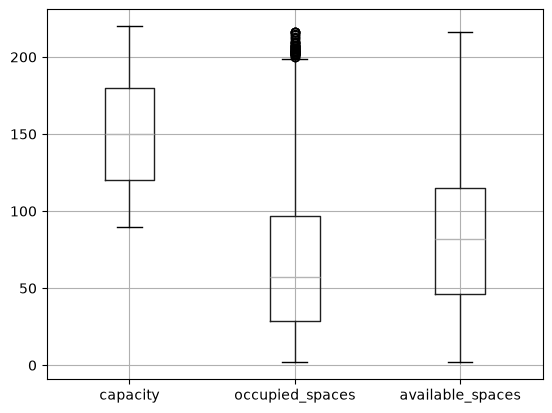

In [21]:
import matplotlib.pyplot as plt

df[['capacity', 'occupied_spaces', 'available_spaces']].boxplot()
plt.show()

In [22]:
df['occupied_spaces'].describe()

count    12000.000000
mean        67.659583
std         49.041965
min          2.000000
25%         29.000000
50%         57.000000
75%         97.000000
max        216.000000
Name: occupied_spaces, dtype: float64

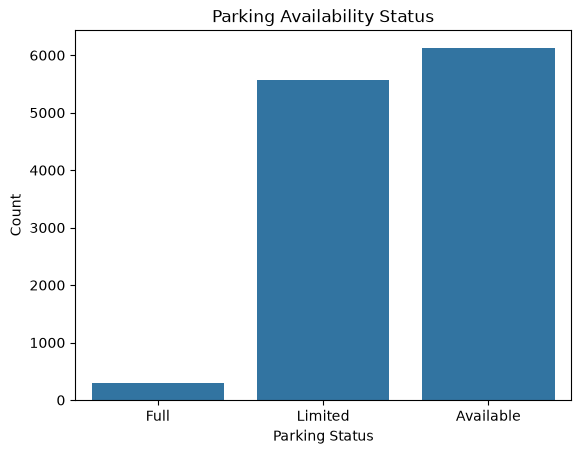

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x='Parking_Status')

plt.title('Parking Availability Status')
plt.xlabel('Parking Status')
plt.ylabel('Count')

plt.show()

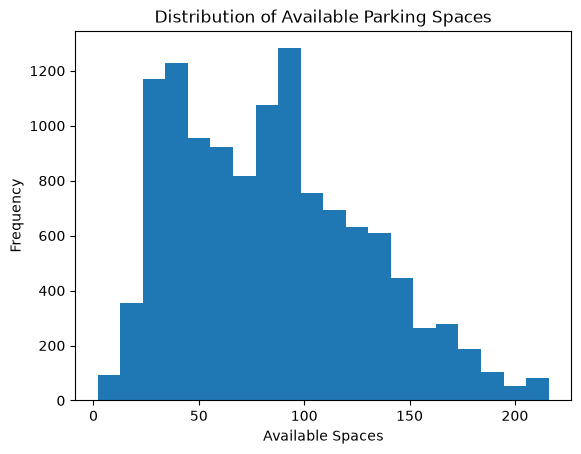

In [24]:
plt.hist(df['available_spaces'], bins=20)

plt.title('Distribution of Available Parking Spaces')
plt.xlabel('Available Spaces')
plt.ylabel('Frequency')

plt.show()

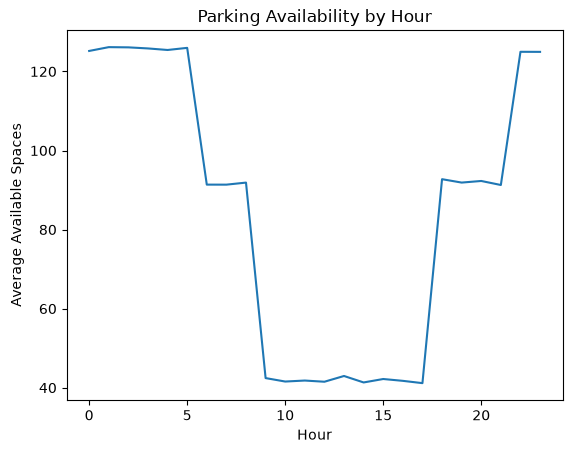

In [25]:
sns.lineplot(data=df, x='hour', y='available_spaces', errorbar=None)

plt.title('Parking Availability by Hour')
plt.xlabel('Hour')
plt.ylabel('Average Available Spaces')

plt.show()

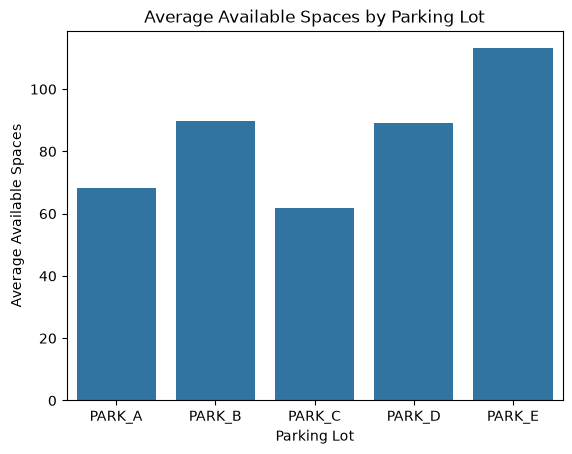

In [27]:
sns.barplot(data=df, x='parking_id', y='available_spaces', errorbar=None)

plt.title('Average Available Spaces by Parking Lot')
plt.xlabel('Parking Lot')
plt.ylabel('Average Available Spaces')

plt.show()

In [28]:
df.head()

,timestamp,parking_id,capacity,occupied_spaces,available_spaces,hour,Parking_Status
0,2024-01-01,PARK_A,120,22,98,0,Available
1,2024-01-01,PARK_B,180,39,141,0,Available
2,2024-01-01,PARK_C,90,2,88,0,Available
3,2024-01-01,PARK_D,150,13,137,0,Available
4,2024-01-01,PARK_E,220,30,190,0,Available


In [29]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   timestamp         12000 non-null  datetime64[us]
 1   parking_id        12000 non-null  str           
 2   capacity          12000 non-null  int64         
 3   occupied_spaces   12000 non-null  int64         
 4   available_spaces  12000 non-null  int64         
 5   hour              12000 non-null  int64         
 6   Parking_Status    12000 non-null  category      
dtypes: category(1), datetime64[us](1), int64(4), str(1)
memory usage: 644.8 KB


In [30]:
df.to_csv('cleaned_parking_data.csv', index=False)